# Automobile Performance & Fuel Efficiency Analysis

**Individual Data Analysis Portfolio Project**

This project analyzes a historical automobile dataset to understand the relationships between fuel efficiency (MPG), vehicle weight, engine size, horsepower, acceleration, model year, cylinders, and manufacturing origin.

### Portfolio goals
- Build a reproducible data-quality and cleaning workflow.
- Translate raw vehicle specifications into clear analytical insights.
- Compare fuel efficiency across origins, cylinder counts, and model years.
- Quantify the strongest relationships with MPG.
- Detect vehicles with unusual acceleration behavior relative to engine displacement.
- Validate the descriptive findings with a simple, interpretable MPG baseline model.
- Export analysis-ready tables and presentation-ready charts.

> **Acceleration note:** in this dataset, acceleration is a time-based measure in seconds. Lower values indicate quicker acceleration.

## 1. Setup & Reproducibility

The project uses relative paths, creates output folders automatically, and fixes the random seed used by the validation model.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
np.random.seed(42)

DATA_PATH = Path("automobile_data.csv")
OUTPUT_DIR = Path("outputs")
CHART_DIR = OUTPUT_DIR / "charts"
OUTPUT_DIR.mkdir(exist_ok=True)
CHART_DIR.mkdir(exist_ok=True)

print(f"Dataset path: {DATA_PATH.resolve()}")
print(f"Charts folder: {CHART_DIR.resolve()}")

Dataset path: /mnt/data/automobile-performance-analysis/automobile_data.csv
Charts folder: /mnt/data/automobile-performance-analysis/outputs/charts


## 2. Load the Dataset

The original file is kept unchanged. Column names are standardized only inside the analytical DataFrame.

In [2]:
raw_df = pd.read_csv(DATA_PATH)

column_map = {
    "Car": "car",
    "MPG": "mpg",
    "Cylinders": "cylinders",
    "Displacement": "displacement",
    "Horsepower": "horsepower",
    "Weight": "weight",
    "Acceleration": "acceleration",
    "Model": "model_year",
    "Origin": "origin",
    "Origin Model": "origin_model",
}

df = raw_df.rename(columns=column_map).copy()

print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
display(df.head())

Rows: 406
Columns: 10


,car,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,origin_model
0,Chevrolet Chevelle Malibu,18.0,8,307.0,130,3504,12.0,70,US,US 70
1,Buick Skylark 320,15.0,8,350.0,165,3693,11.5,70,US,US 70
2,Plymouth Satellite,18.0,8,318.0,150,3436,11.0,70,US,US 70
3,AMC Rebel SST,16.0,8,304.0,150,3433,12.0,70,US,US 70
4,Ford Torino,17.0,8,302.0,140,3449,10.5,70,US,US 70


## 3. Data Quality Assessment

The source data uses `0` as a placeholder for unavailable MPG and horsepower observations. These values are not physically meaningful here, so they are treated as missing rather than real zeros.

In [3]:
quality_before = pd.DataFrame({
    "metric": [
        "rows", "columns", "duplicate_rows",
        "mpg_zero_placeholders", "horsepower_zero_placeholders"
    ],
    "value": [
        len(df), df.shape[1], int(df.duplicated().sum()),
        int((df["mpg"] == 0).sum()), int((df["horsepower"] == 0).sum())
    ]
})

display(quality_before)
print("\nData types:")
display(df.dtypes.to_frame("dtype"))

,metric,value
0,rows,406
1,columns,10
2,duplicate_rows,0
3,mpg_zero_placeholders,8
4,horsepower_zero_placeholders,6



Data types:


,dtype
car,object
mpg,float64
cylinders,int64
displacement,float64
horsepower,int64
weight,int64
acceleration,float64
model_year,int64
origin,object
origin_model,object


## 4. Cleaning & Feature Preparation

Cleaning decisions are conservative: rows are retained, invalid zero placeholders are converted to missing values, text fields are stripped, and model years are converted from two-digit values (70-82) to full years (1970-1982). The redundant `origin_model` field is retained in the raw file but excluded from the analytical dataset because it can be reconstructed from origin and model year.

In [4]:
analysis_df = df.copy()

analysis_df["car"] = analysis_df["car"].astype(str).str.strip()
analysis_df["origin"] = analysis_df["origin"].astype(str).str.strip()
analysis_df["mpg"] = analysis_df["mpg"].replace(0, np.nan)
analysis_df["horsepower"] = analysis_df["horsepower"].replace(0, np.nan)
analysis_df["model_year"] = analysis_df["model_year"].apply(
    lambda year: year + 1900 if year < 1900 else year
)

# Derived analytical feature
analysis_df["horsepower_per_1000_lb"] = (
    analysis_df["horsepower"] / analysis_df["weight"] * 1000
)

# Remove redundant compound field from the analytical table
analysis_df = analysis_df.drop(columns=["origin_model"])

missing_after = analysis_df.isna().sum().rename("missing_values").to_frame()
missing_after["missing_pct"] = (missing_after["missing_values"] / len(analysis_df) * 100).round(2)

display(missing_after[missing_after["missing_values"] > 0])
print(f"Duplicate rows after cleaning: {analysis_df.duplicated().sum()}")
print(f"Model year range: {analysis_df['model_year'].min()} - {analysis_df['model_year'].max()}")

analysis_df.to_csv(OUTPUT_DIR / "cleaned_automobile_data.csv", index=False)

,missing_values,missing_pct
mpg,8,1.97
horsepower,6,1.48
horsepower_per_1000_lb,6,1.48


Duplicate rows after cleaning: 0
Model year range: 1970 - 1982


## 5. Descriptive Overview & KPIs

This section provides a quick executive view of the dataset before deeper analysis.

In [5]:
summary_stats = analysis_df[[
    "mpg", "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year", "horsepower_per_1000_lb"
]].describe().T.round(2)
summary_stats.to_csv(OUTPUT_DIR / "summary_statistics.csv")
display(summary_stats)

origin_mpg = analysis_df.groupby("origin")["mpg"].mean().sort_values(ascending=False)
cylinder_mpg = analysis_df.groupby("cylinders")["mpg"].mean().sort_values(ascending=False)
yearly_mpg = analysis_df.groupby("model_year")["mpg"].mean()

kpis = pd.DataFrame({
    "metric": [
        "Total vehicles",
        "Valid MPG observations",
        "Valid horsepower observations",
        "Average MPG",
        "Median MPG",
        "Average vehicle weight (lb)",
        "Highest average-MPG origin",
        "Highest average-MPG cylinder group",
        "MPG change: 1970 to 1982"
    ],
    "value": [
        f"{len(analysis_df):,}",
        f"{analysis_df['mpg'].notna().sum():,}",
        f"{analysis_df['horsepower'].notna().sum():,}",
        f"{analysis_df['mpg'].mean():.2f}",
        f"{analysis_df['mpg'].median():.2f}",
        f"{analysis_df['weight'].mean():,.0f}",
        f"{origin_mpg.index[0]} ({origin_mpg.iloc[0]:.2f} MPG)",
        f"{int(cylinder_mpg.index[0])} cylinders ({cylinder_mpg.iloc[0]:.2f} MPG)",
        f"{((yearly_mpg.loc[1982] / yearly_mpg.loc[1970]) - 1) * 100:.1f}%"
    ]
})
kpis.to_csv(OUTPUT_DIR / "kpi_summary.csv", index=False)
display(kpis)

,count,mean,std,min,25%,50%,75%,max
mpg,398.0,23.51,7.82,9.00,17.50,23.00,29.00,46.60
cylinders,406.0,5.48,1.71,3.00,4.00,4.00,8.00,8.00
displacement,406.0,194.78,104.92,68.00,105.00,151.00,302.00,455.00
horsepower,400.0,105.08,38.77,46.00,75.75,95.00,130.00,230.00
weight,406.0,2979.41,847.00,1613.00,2226.50,2822.50,3618.25,5140.00
acceleration,406.0,15.52,2.80,8.00,13.70,15.50,17.18,24.80
model_year,406.0,1975.92,3.75,1970.00,1973.00,1976.00,1979.00,1982.00
horsepower_per_1000_lb,400.0,34.91,5.96,20.56,30.90,34.37,38.24,72.91


,metric,value
0,Total vehicles,406
1,Valid MPG observations,398
2,Valid horsepower observations,400
3,Average MPG,23.51
4,Median MPG,23.00
5,Average vehicle weight (lb),"2,979"
6,Highest average-MPG origin,Japan (30.45 MPG)
7,Highest average-MPG cylinder group,4 cylinders (29.29 MPG)
8,MPG change: 1970 to 1982,79.3%


## 6. Fuel Efficiency Distribution

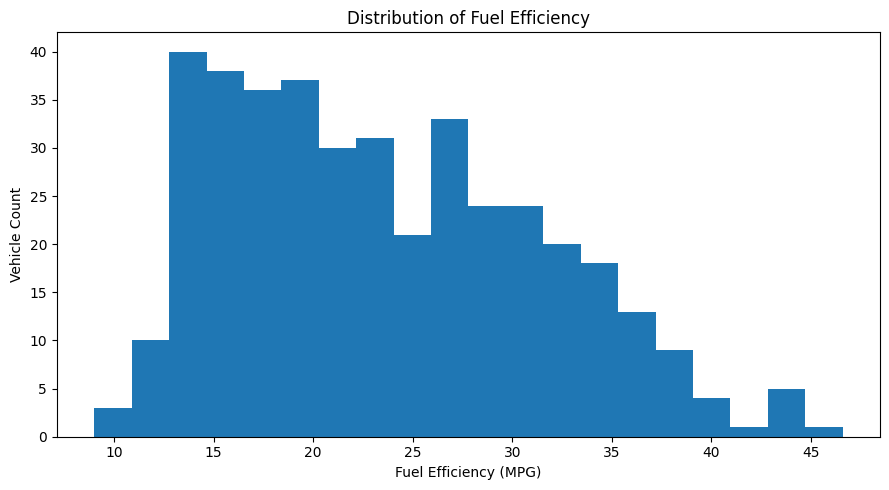

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(analysis_df["mpg"].dropna(), bins=20)
ax.set_title("Distribution of Fuel Efficiency")
ax.set_xlabel("Fuel Efficiency (MPG)")
ax.set_ylabel("Vehicle Count")
fig.tight_layout()
fig.savefig(CHART_DIR / "01_mpg_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

## 7. Fuel Efficiency by Origin & Cylinder Count

Comparing average MPG across manufacturing origins and cylinder counts helps reveal broad efficiency differences between vehicle groups.

,vehicles,valid_mpg,avg_mpg,median_mpg,avg_weight_lb,avg_horsepower
origin,,,,,,
Japan,79,79,30.45,31.6,2221.23,79.84
Europe,73,70,27.89,26.5,2431.49,81.00
US,254,249,20.08,18.5,3372.70,119.90


,vehicles,valid_mpg,avg_mpg,avg_weight_lb,avg_horsepower
cylinders,,,,,
4,207,204,29.29,2312.69,78.47
5,3,3,27.37,3103.33,82.33
3,4,4,20.55,2398.50,99.25
6,84,84,19.99,3198.23,101.51
8,108,103,14.96,4105.19,158.45


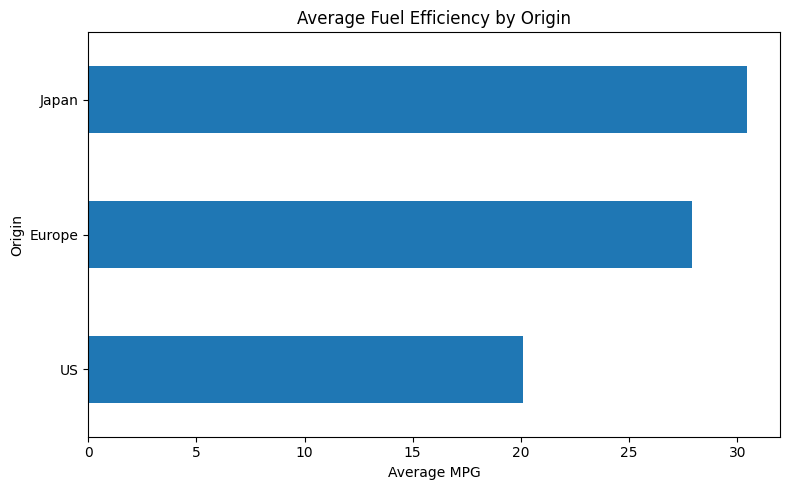

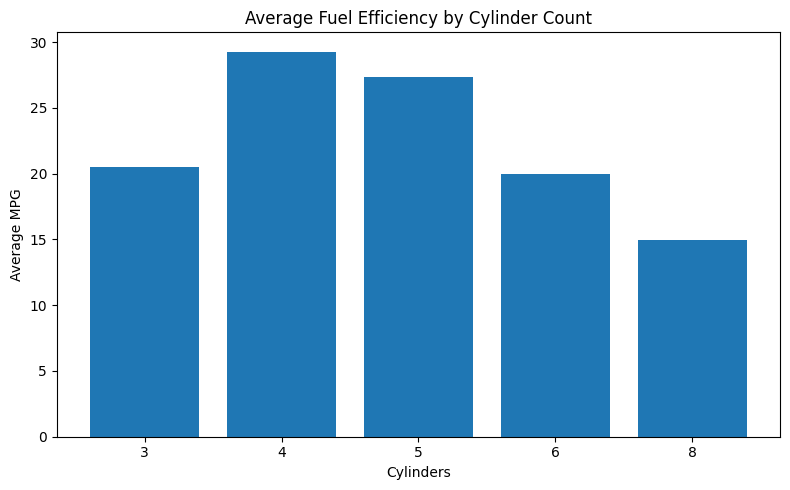

In [7]:
origin_summary = analysis_df.groupby("origin").agg(
    vehicles=("car", "count"),
    valid_mpg=("mpg", "count"),
    avg_mpg=("mpg", "mean"),
    median_mpg=("mpg", "median"),
    avg_weight_lb=("weight", "mean"),
    avg_horsepower=("horsepower", "mean")
).round(2).sort_values("avg_mpg", ascending=False)
origin_summary.to_csv(OUTPUT_DIR / "origin_summary.csv")
display(origin_summary)

cylinder_summary = analysis_df.groupby("cylinders").agg(
    vehicles=("car", "count"),
    valid_mpg=("mpg", "count"),
    avg_mpg=("mpg", "mean"),
    avg_weight_lb=("weight", "mean"),
    avg_horsepower=("horsepower", "mean")
).round(2).sort_values("avg_mpg", ascending=False)
cylinder_summary.to_csv(OUTPUT_DIR / "cylinder_summary.csv")
display(cylinder_summary)

fig, ax = plt.subplots(figsize=(8, 5))
origin_summary["avg_mpg"].sort_values().plot(kind="barh", ax=ax)
ax.set_title("Average Fuel Efficiency by Origin")
ax.set_xlabel("Average MPG")
ax.set_ylabel("Origin")
fig.tight_layout()
fig.savefig(CHART_DIR / "02_average_mpg_by_origin.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
cylinder_plot = cylinder_summary.sort_index()
ax.bar(cylinder_plot.index.astype(str), cylinder_plot["avg_mpg"])
ax.set_title("Average Fuel Efficiency by Cylinder Count")
ax.set_xlabel("Cylinders")
ax.set_ylabel("Average MPG")
fig.tight_layout()
fig.savefig(CHART_DIR / "03_average_mpg_by_cylinders.png", dpi=180, bbox_inches="tight")
plt.show()

## 8. What Drives Fuel Efficiency?

Weight, engine displacement, horsepower, and cylinder count are examined against MPG. Regression trend lines are descriptive, not causal.

,mpg
weight,-0.832
displacement,-0.804
horsepower,-0.778
cylinders,-0.775
acceleration,0.420
model_year,0.579
mpg,1.000


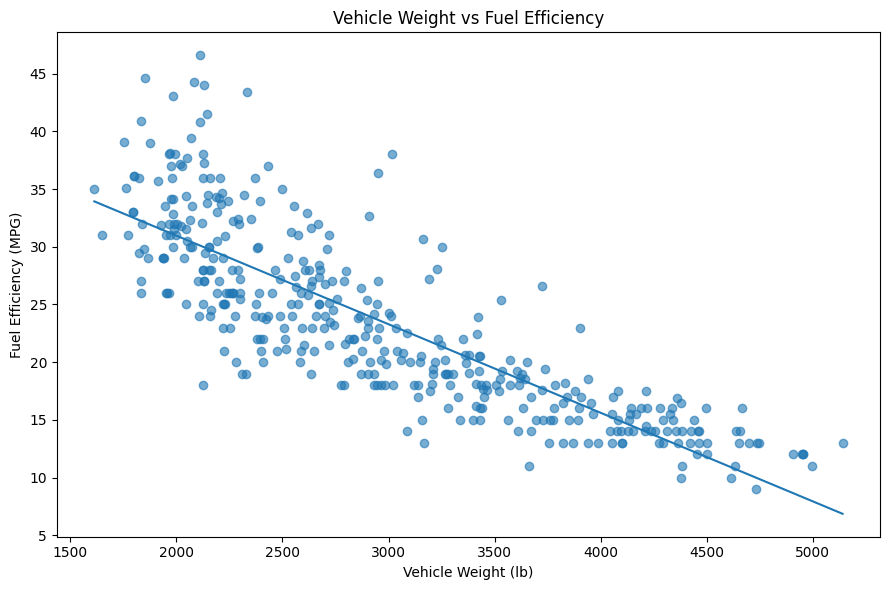

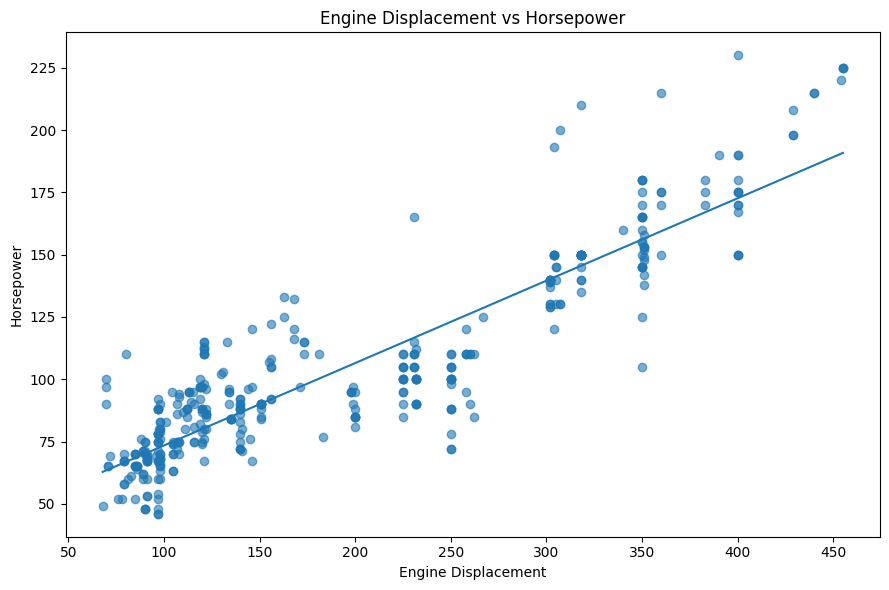

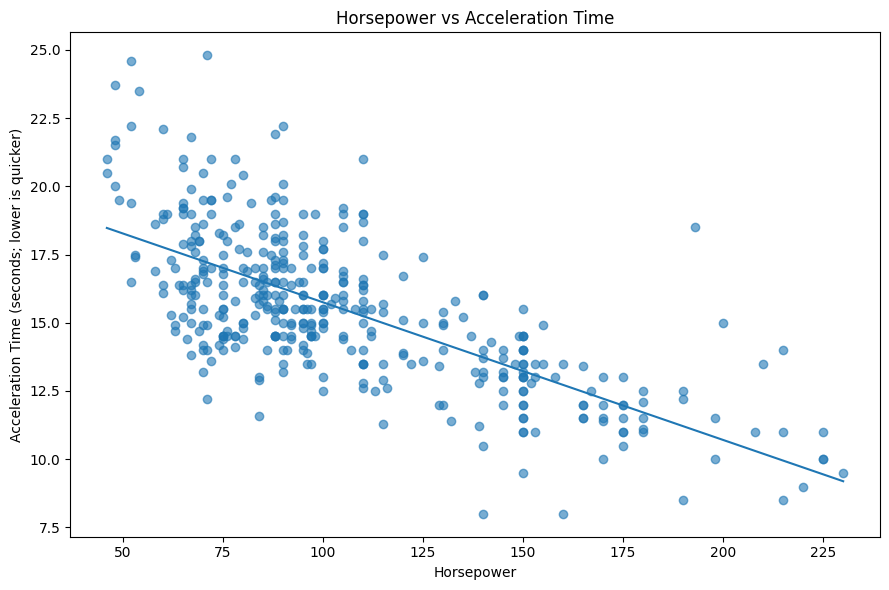

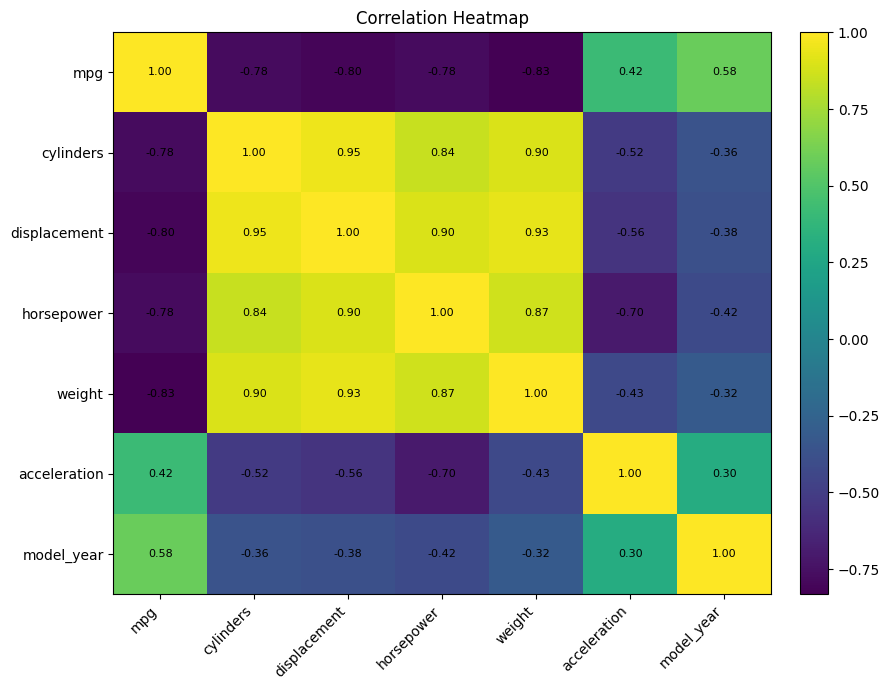

In [8]:
key_corr = analysis_df[[
    "mpg", "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year"
]].corr().round(3)
key_corr.to_csv(OUTPUT_DIR / "correlation_matrix.csv")

display(key_corr[["mpg"]].sort_values("mpg"))

fig, ax = plt.subplots(figsize=(9, 6))
weight_mpg = analysis_df[["weight", "mpg"]].dropna()
ax.scatter(weight_mpg["weight"], weight_mpg["mpg"], alpha=0.6)
coef = np.polyfit(weight_mpg["weight"], weight_mpg["mpg"], 1)
line_x = np.linspace(weight_mpg["weight"].min(), weight_mpg["weight"].max(), 200)
ax.plot(line_x, coef[0] * line_x + coef[1])
ax.set_title("Vehicle Weight vs Fuel Efficiency")
ax.set_xlabel("Vehicle Weight (lb)")
ax.set_ylabel("Fuel Efficiency (MPG)")
fig.tight_layout()
fig.savefig(CHART_DIR / "04_weight_vs_mpg.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 6))
dis_hp = analysis_df[["displacement", "horsepower"]].dropna()
ax.scatter(dis_hp["displacement"], dis_hp["horsepower"], alpha=0.6)
coef = np.polyfit(dis_hp["displacement"], dis_hp["horsepower"], 1)
line_x = np.linspace(dis_hp["displacement"].min(), dis_hp["displacement"].max(), 200)
ax.plot(line_x, coef[0] * line_x + coef[1])
ax.set_title("Engine Displacement vs Horsepower")
ax.set_xlabel("Engine Displacement")
ax.set_ylabel("Horsepower")
fig.tight_layout()
fig.savefig(CHART_DIR / "05_displacement_vs_horsepower.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 6))
hp_acc = analysis_df[["horsepower", "acceleration"]].dropna()
ax.scatter(hp_acc["horsepower"], hp_acc["acceleration"], alpha=0.6)
coef = np.polyfit(hp_acc["horsepower"], hp_acc["acceleration"], 1)
line_x = np.linspace(hp_acc["horsepower"].min(), hp_acc["horsepower"].max(), 200)
ax.plot(line_x, coef[0] * line_x + coef[1])
ax.set_title("Horsepower vs Acceleration Time")
ax.set_xlabel("Horsepower")
ax.set_ylabel("Acceleration Time (seconds; lower is quicker)")
fig.tight_layout()
fig.savefig(CHART_DIR / "06_horsepower_vs_acceleration.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(key_corr.values, aspect="auto")
ax.set_xticks(range(len(key_corr.columns)))
ax.set_xticklabels(key_corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(key_corr.index)))
ax.set_yticklabels(key_corr.index)
for i in range(key_corr.shape[0]):
    for j in range(key_corr.shape[1]):
        ax.text(j, i, f"{key_corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
ax.set_title("Correlation Heatmap")
fig.tight_layout()
fig.savefig(CHART_DIR / "07_correlation_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

## 9. Trends Over Time

Historical trends show how vehicle efficiency and physical characteristics changed across the 1970-1982 model years.

,vehicle_count,avg_mpg,avg_weight_lb,avg_horsepower,avg_displacement
model_year,,,,,
1970,35,17.69,3441.31,148.86,286.86
1971,29,21.25,2960.34,104.93,205.86
1972,28,18.71,3237.71,120.18,218.38
1973,40,17.10,3419.02,130.48,256.88
1974,27,22.70,2877.93,94.23,171.74
1975,30,20.27,3176.80,101.07,205.53
1976,34,21.57,3078.74,101.12,197.79
1977,28,23.38,2997.36,105.07,191.39
1978,36,24.06,2861.81,99.69,177.81


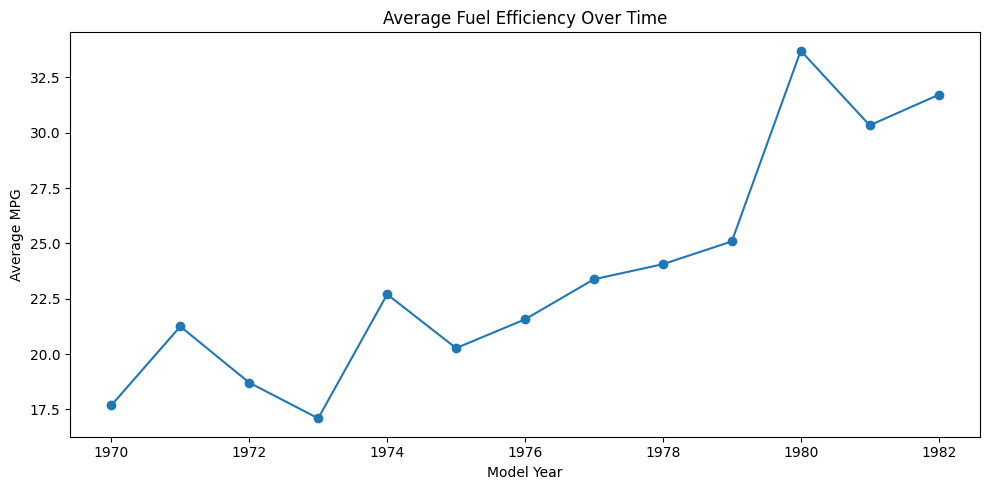

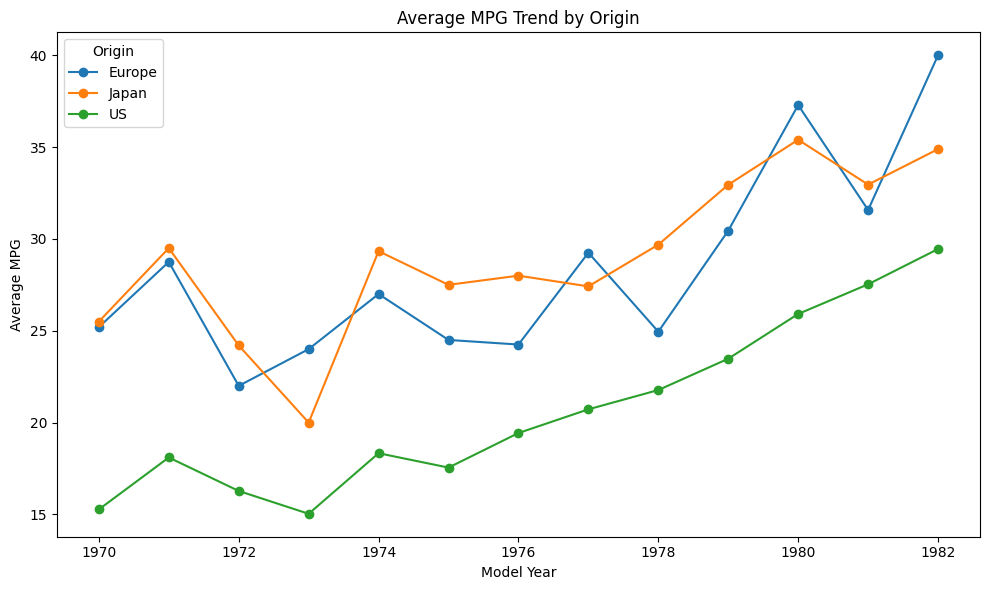

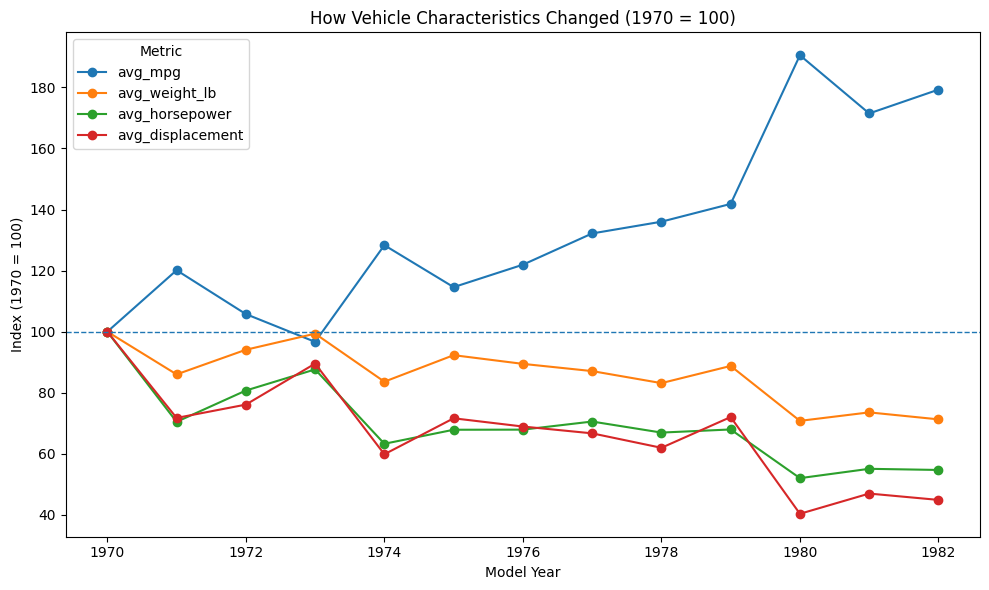

In [9]:
yearly_trends = analysis_df.groupby("model_year").agg(
    vehicle_count=("car", "count"),
    avg_mpg=("mpg", "mean"),
    avg_weight_lb=("weight", "mean"),
    avg_horsepower=("horsepower", "mean"),
    avg_displacement=("displacement", "mean")
).round(2)
yearly_trends.to_csv(OUTPUT_DIR / "yearly_trends.csv")
display(yearly_trends)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(yearly_trends.index, yearly_trends["avg_mpg"], marker="o")
ax.set_title("Average Fuel Efficiency Over Time")
ax.set_xlabel("Model Year")
ax.set_ylabel("Average MPG")
fig.tight_layout()
fig.savefig(CHART_DIR / "08_mpg_trend_over_time.png", dpi=180, bbox_inches="tight")
plt.show()

origin_year = analysis_df.groupby(["model_year", "origin"])["mpg"].mean().unstack()
origin_year.to_csv(OUTPUT_DIR / "origin_mpg_trends.csv")

fig, ax = plt.subplots(figsize=(10, 6))
origin_year.plot(marker="o", ax=ax)
ax.set_title("Average MPG Trend by Origin")
ax.set_xlabel("Model Year")
ax.set_ylabel("Average MPG")
ax.legend(title="Origin")
fig.tight_layout()
fig.savefig(CHART_DIR / "09_mpg_trend_by_origin.png", dpi=180, bbox_inches="tight")
plt.show()

# Index major characteristics to 1970 = 100 for comparable trend scales.
indexed = yearly_trends[["avg_mpg", "avg_weight_lb", "avg_horsepower", "avg_displacement"]].copy()
indexed = indexed / indexed.loc[1970] * 100
fig, ax = plt.subplots(figsize=(10, 6))
indexed.plot(marker="o", ax=ax)
ax.axhline(100, linestyle="--", linewidth=1)
ax.set_title("How Vehicle Characteristics Changed (1970 = 100)")
ax.set_xlabel("Model Year")
ax.set_ylabel("Index (1970 = 100)")
ax.legend(title="Metric")
fig.tight_layout()
fig.savefig(CHART_DIR / "10_vehicle_characteristics_indexed.png", dpi=180, bbox_inches="tight")
plt.show()

## 10. MPG Improvement Rate by Origin

For comparability, improvement is defined as the slope of a simple linear trend in average MPG versus model year. This is a descriptive trend measure, not a causal estimate.

In [10]:
improvement_rows = []
for origin in origin_year.columns:
    series = origin_year[origin].dropna()
    slope, intercept = np.polyfit(series.index, series.values, 1)
    improvement_rows.append({
        "origin": origin,
        "mpg_improvement_per_year": slope,
        "trend_intercept": intercept,
        "years_observed": int(series.shape[0])
    })

improvement = pd.DataFrame(improvement_rows).sort_values(
    "mpg_improvement_per_year", ascending=False
).reset_index(drop=True)
improvement.to_csv(OUTPUT_DIR / "mpg_improvement_by_origin.csv", index=False)
display(improvement.round(3))

,origin,mpg_improvement_per_year,trend_intercept,years_observed
0,US,1.133,-2217.473,13
1,Europe,1.011,-1970.188,13
2,Japan,0.868,-1685.317,13


## 11. Acceleration Residual Outlier Analysis

Instead of calling these vehicles general outliers, this analysis asks a specific question: **which vehicles have acceleration times that are unusually different from what engine displacement alone would predict?**

A linear displacement-acceleration relationship is estimated and observations with absolute residuals greater than two residual standard deviations are flagged.

,car,origin,model_year,displacement,acceleration,expected_acceleration,acceleration_residual,is_residual_outlier
17,Ford Mustang Boss 302,US,1970,302.0,8.0,13.92,-5.92,True
16,Plymouth 'Cuda 340,US,1970,340.0,8.0,13.35,-5.35,True
341,Mazda RX-7 GS,Japan,1980,70.0,12.5,17.38,-4.88,True
403,Dodge Rampage,US,1982,135.0,11.6,16.41,-4.81,True
210,Volkswagen Rabbit,Europe,1976,97.0,12.2,16.98,-4.78,True
162,Ford Maverick,US,1975,250.0,19.5,14.70,4.80,True
202,Chevrolet Chevette,US,1976,85.0,22.2,17.16,5.04,True
203,Chevrolet Woody,US,1976,98.0,22.1,16.96,5.14,True
216,Peugeot 504,Europe,1976,120.0,21.9,16.63,5.27,True
335,Mercedes-Benz 240d,Europe,1980,146.0,21.8,16.25,5.55,True


Residual outliers detected: 19
Residual threshold: ±4.65 seconds


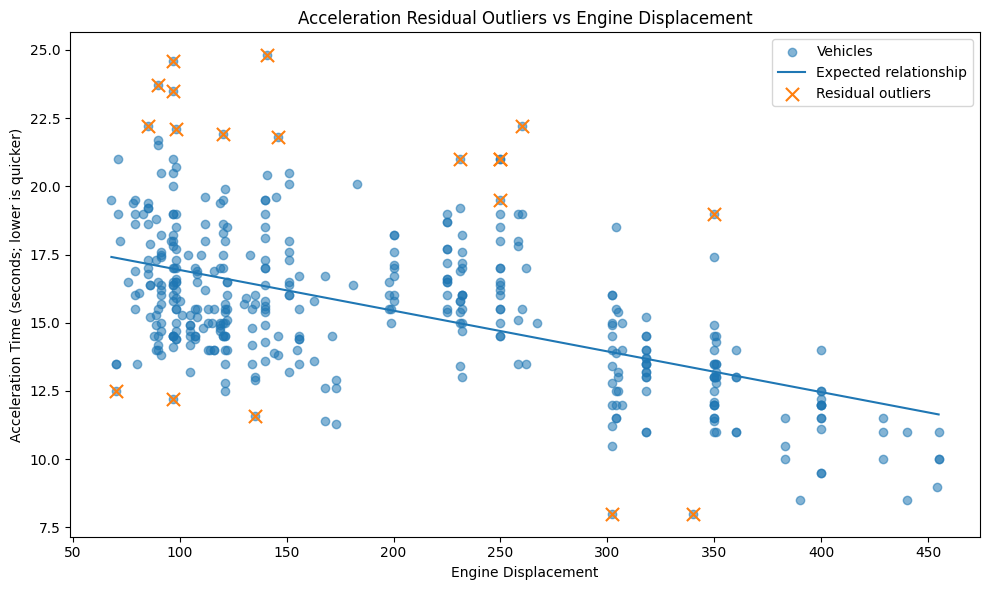

In [11]:
accel_data = analysis_df[["car", "origin", "model_year", "displacement", "acceleration"]].dropna().copy()

slope, intercept = np.polyfit(accel_data["displacement"], accel_data["acceleration"], 1)
accel_data["expected_acceleration"] = slope * accel_data["displacement"] + intercept
accel_data["acceleration_residual"] = accel_data["acceleration"] - accel_data["expected_acceleration"]
residual_threshold = 2 * accel_data["acceleration_residual"].std(ddof=1)
accel_data["is_residual_outlier"] = accel_data["acceleration_residual"].abs() > residual_threshold

acceleration_outliers = accel_data[accel_data["is_residual_outlier"]].copy()
acceleration_outliers = acceleration_outliers.sort_values("acceleration_residual")
acceleration_outliers.to_csv(OUTPUT_DIR / "acceleration_residual_outliers.csv", index=False)

display(acceleration_outliers.round(2))
print(f"Residual outliers detected: {len(acceleration_outliers)}")
print(f"Residual threshold: ±{residual_threshold:.2f} seconds")

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(accel_data["displacement"], accel_data["acceleration"], alpha=0.55, label="Vehicles")
line_x = np.linspace(accel_data["displacement"].min(), accel_data["displacement"].max(), 200)
ax.plot(line_x, slope * line_x + intercept, label="Expected relationship")
ax.scatter(
    acceleration_outliers["displacement"],
    acceleration_outliers["acceleration"],
    marker="x", s=90, label="Residual outliers"
)
ax.set_title("Acceleration Residual Outliers vs Engine Displacement")
ax.set_xlabel("Engine Displacement")
ax.set_ylabel("Acceleration Time (seconds; lower is quicker)")
ax.legend()
fig.tight_layout()
fig.savefig(CHART_DIR / "11_acceleration_residual_outliers.png", dpi=180, bbox_inches="tight")
plt.show()

## 12. Analytical Validation: Baseline MPG Model

A compact Ridge Regression baseline is used to validate whether the descriptive relationships jointly explain MPG. The purpose is **analytical validation**, not production forecasting.

- Numeric missing horsepower values are median-imputed inside the model pipeline only.
- Numeric features are standardized.
- Origin is one-hot encoded.
- Model quality is evaluated with a held-out test set and 5-fold cross-validation.
- Permutation importance is used to show which input variables matter most to the fitted model without relying on raw coefficient magnitudes.

,metric,value
0,Test R²,0.845
1,Test MAE (MPG),2.277
2,5-fold CV R²,0.814
3,5-fold CV MAE (MPG),2.562
4,Selected Ridge alpha,2.024


,feature,importance_mean,importance_std
3,weight,1.1012,0.1239
5,model_year,0.2989,0.0440
1,displacement,0.1231,0.0192
6,origin,0.0455,0.0131
2,horsepower,0.0061,0.0074
4,acceleration,-0.0001,0.0012
0,cylinders,-0.0011,0.0024


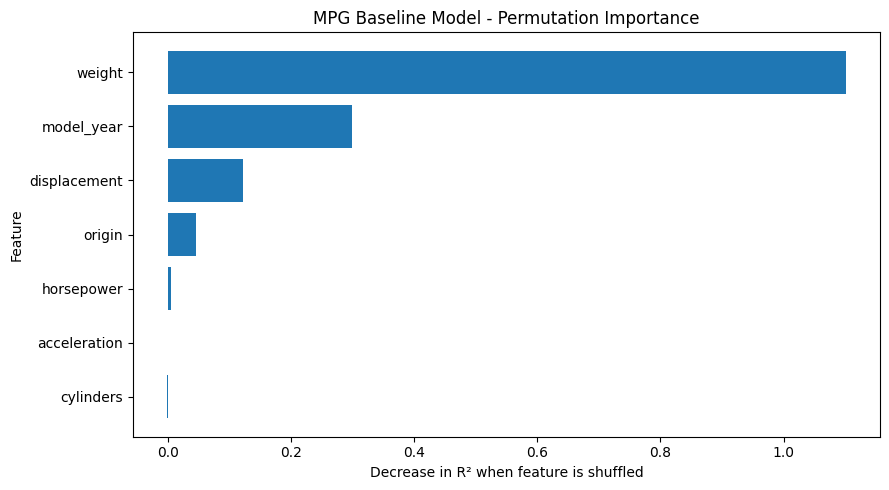

In [12]:
model_df = analysis_df.dropna(subset=["mpg"]).copy()
feature_columns = [
    "cylinders", "displacement", "horsepower", "weight",
    "acceleration", "model_year", "origin"
]
X = model_df[feature_columns]
y = model_df["mpg"]

numeric_features = [
    "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year"
]
categorical_features = ["origin"]

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features)
])

ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RidgeCV(alphas=np.logspace(-3, 3, 50)))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
ridge_model.fit(X_train, y_train)
test_predictions = ridge_model.predict(X_test)

cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_r2 = cross_val_score(ridge_model, X, y, cv=cv, scoring="r2")
cv_mae = -cross_val_score(ridge_model, X, y, cv=cv, scoring="neg_mean_absolute_error")

model_metrics = pd.DataFrame({
    "metric": ["Test R²", "Test MAE (MPG)", "5-fold CV R²", "5-fold CV MAE (MPG)", "Selected Ridge alpha"],
    "value": [
        r2_score(y_test, test_predictions),
        mean_absolute_error(y_test, test_predictions),
        cv_r2.mean(),
        cv_mae.mean(),
        ridge_model.named_steps["model"].alpha_
    ]
})
model_metrics.to_csv(OUTPUT_DIR / "mpg_baseline_model_metrics.csv", index=False)
display(model_metrics.round(3))

importance_result = permutation_importance(
    ridge_model, X_test, y_test,
    n_repeats=30, random_state=42, scoring="r2"
)
importance_df = pd.DataFrame({
    "feature": feature_columns,
    "importance_mean": importance_result.importances_mean,
    "importance_std": importance_result.importances_std
}).sort_values("importance_mean", ascending=False)
importance_df.to_csv(OUTPUT_DIR / "mpg_model_permutation_importance.csv", index=False)
display(importance_df.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
plot_importance = importance_df.sort_values("importance_mean")
ax.barh(plot_importance["feature"], plot_importance["importance_mean"])
ax.set_title("MPG Baseline Model - Permutation Importance")
ax.set_xlabel("Decrease in R² when feature is shuffled")
ax.set_ylabel("Feature")
fig.tight_layout()
fig.savefig(CHART_DIR / "12_mpg_model_permutation_importance.png", dpi=180, bbox_inches="tight")
plt.show()

## 13. High-Efficiency Vehicles

A short list of the most fuel-efficient valid observations provides an intuitive reference point for the distribution-level findings.

In [13]:
top_efficiency = analysis_df.nlargest(15, "mpg")[[
    "car", "mpg", "origin", "model_year", "cylinders",
    "weight", "horsepower", "displacement"
]].copy()
top_efficiency.to_csv(OUTPUT_DIR / "top_15_fuel_efficient_vehicles.csv", index=False)
display(top_efficiency)

,car,mpg,origin,model_year,cylinders,weight,horsepower,displacement
329,Mazda GLC,46.6,Japan,1980,4,2110,65.0,86.0
336,Honda Civic 1500 gl,44.6,Japan,1980,4,1850,67.0,91.0
332,Volkswagen Rabbit C (Diesel),44.3,Europe,1980,4,2085,48.0,90.0
402,Volkswagen Pickup,44.0,Europe,1982,4,2130,52.0,97.0
333,Volkswagen Dasher (diesel),43.4,Europe,1980,4,2335,48.0,90.0
251,Volkswagen Rabbit Custom Diesel,43.1,Europe,1978,4,1985,48.0,90.0
316,Volkswagen Rabbit,41.5,Europe,1980,4,2144,76.0,98.0
337,Renault Lecar Deluxe,40.9,Europe,1980,4,1835,NaN,85.0
331,Datsun 210,40.8,Japan,1980,4,2110,65.0,85.0
254,Datsun B210 GX,39.4,Japan,1978,4,2070,70.0,85.0


## 14. Key Findings & Analytical Takeaways

In [14]:
mpg_corr = analysis_df[[
    "mpg", "weight", "displacement", "horsepower", "cylinders", "model_year", "acceleration"
]].corr()["mpg"]

start_year = yearly_trends.index.min()
end_year = yearly_trends.index.max()
mpg_change = (yearly_trends.loc[end_year, "avg_mpg"] / yearly_trends.loc[start_year, "avg_mpg"] - 1) * 100
weight_change = (yearly_trends.loc[end_year, "avg_weight_lb"] / yearly_trends.loc[start_year, "avg_weight_lb"] - 1) * 100
hp_change = (yearly_trends.loc[end_year, "avg_horsepower"] / yearly_trends.loc[start_year, "avg_horsepower"] - 1) * 100

best_origin = origin_summary["avg_mpg"].idxmax()
best_origin_mpg = origin_summary.loc[best_origin, "avg_mpg"]
heaviest_origin = origin_summary["avg_weight_lb"].idxmax()
fastest_improving_origin = improvement.iloc[0]["origin"]
fastest_improving_slope = improvement.iloc[0]["mpg_improvement_per_year"]

insights = f"""
### Executive findings

1. **Weight is the strongest simple MPG relationship** in the dataset: correlation = **{mpg_corr['weight']:.2f}**. Heavier vehicles are strongly associated with lower fuel efficiency.
2. **Engine size and power are also strongly associated with lower MPG**: displacement correlation = **{mpg_corr['displacement']:.2f}**, horsepower correlation = **{mpg_corr['horsepower']:.2f}**.
3. **Fuel efficiency improved substantially over time**: average MPG increased by **{mpg_change:.1f}%** from {start_year} to {end_year}.
4. Over the same period, average vehicle weight changed by **{weight_change:.1f}%** and average horsepower by **{hp_change:.1f}%**, consistent with a shift toward lighter, less power-intensive vehicles.
5. **{best_origin} has the highest average MPG** at **{best_origin_mpg:.2f} MPG**, while **{heaviest_origin}** has the highest average vehicle weight.
6. Using linear MPG trend slope, **{fastest_improving_origin}** shows the fastest average improvement at approximately **{fastest_improving_slope:.2f} MPG per model year**.
7. The displacement-based acceleration residual analysis flags **{len(acceleration_outliers)} vehicles** with unusually fast or slow acceleration times relative to displacement alone.
8. The baseline MPG model achieves a **test R² of {r2_score(y_test, test_predictions):.2f}** and **MAE of {mean_absolute_error(y_test, test_predictions):.2f} MPG**, supporting the descriptive finding that the selected vehicle characteristics jointly explain a large share of MPG variation in this sample.

### Practical interpretation

- Vehicle mass is a central efficiency trade-off in this historical dataset.
- The long-term efficiency improvement is accompanied by substantial reductions in average weight, horsepower, and displacement.
- Origin differences are meaningful at the group level, but they should not be interpreted as causal because vehicle mix differs across origins and model years.
- Residual outliers are useful candidates for case-level inspection because they behave differently from the broad engine-size/acceleration relationship.
"""
display(Markdown(insights))


### Executive findings

1. **Weight is the strongest simple MPG relationship** in the dataset: correlation = **-0.83**. Heavier vehicles are strongly associated with lower fuel efficiency.
2. **Engine size and power are also strongly associated with lower MPG**: displacement correlation = **-0.80**, horsepower correlation = **-0.78**.
3. **Fuel efficiency improved substantially over time**: average MPG increased by **79.3%** from 1970 to 1982.
4. Over the same period, average vehicle weight changed by **-28.7%** and average horsepower by **-45.3%**, consistent with a shift toward lighter, less power-intensive vehicles.
5. **Japan has the highest average MPG** at **30.45 MPG**, while **US** has the highest average vehicle weight.
6. Using linear MPG trend slope, **US** shows the fastest average improvement at approximately **1.13 MPG per model year**.
7. The displacement-based acceleration residual analysis flags **19 vehicles** with unusually fast or slow acceleration times relative to displacement alone.
8. The baseline MPG model achieves a **test R² of 0.85** and **MAE of 2.28 MPG**, supporting the descriptive finding that the selected vehicle characteristics jointly explain a large share of MPG variation in this sample.

### Practical interpretation

- Vehicle mass is a central efficiency trade-off in this historical dataset.
- The long-term efficiency improvement is accompanied by substantial reductions in average weight, horsepower, and displacement.
- Origin differences are meaningful at the group level, but they should not be interpreted as causal because vehicle mix differs across origins and model years.
- Residual outliers are useful candidates for case-level inspection because they behave differently from the broad engine-size/acceleration relationship.


## 15. Export Audit

All important analytical outputs are saved under `outputs/`, while charts are stored in `outputs/charts/` for direct use in GitHub, reports, and freelance portfolio pages.

In [15]:
quality_export = quality_before.copy()
quality_export.to_csv(OUTPUT_DIR / "data_quality_summary.csv", index=False)

exported_files = sorted(path.as_posix() for path in OUTPUT_DIR.rglob("*") if path.is_file())
print(f"Exported files: {len(exported_files)}")
for file_name in exported_files:
    print("-", file_name)

Exported files: 26
- outputs/acceleration_residual_outliers.csv
- outputs/charts/01_mpg_distribution.png
- outputs/charts/02_average_mpg_by_origin.png
- outputs/charts/03_average_mpg_by_cylinders.png
- outputs/charts/04_weight_vs_mpg.png
- outputs/charts/05_displacement_vs_horsepower.png
- outputs/charts/06_horsepower_vs_acceleration.png
- outputs/charts/07_correlation_heatmap.png
- outputs/charts/08_mpg_trend_over_time.png
- outputs/charts/09_mpg_trend_by_origin.png
- outputs/charts/10_vehicle_characteristics_indexed.png
- outputs/charts/11_acceleration_residual_outliers.png
- outputs/charts/12_mpg_model_permutation_importance.png
- outputs/cleaned_automobile_data.csv
- outputs/correlation_matrix.csv
- outputs/cylinder_summary.csv
- outputs/data_quality_summary.csv
- outputs/kpi_summary.csv
- outputs/mpg_baseline_model_metrics.csv
- outputs/mpg_improvement_by_origin.csv
- outputs/mpg_model_permutation_importance.csv
- outputs/origin_mpg_trends.csv
- outputs/origin_summary.csv
- output